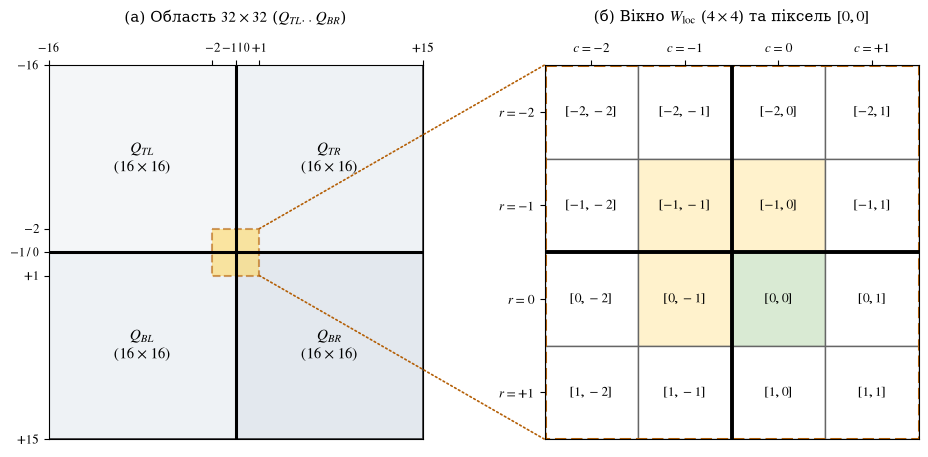

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import ConnectionPatch

plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'stix'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={'width_ratios': [1, 1.15]})

# --- ЛІВА ПАНЕЛЬ: Макротопологія 32x32 ---
ax1.set_xlim(-16, 16)
ax1.set_ylim(16, -16)  # Вісь r спрямована вниз (як у матриці зображення)
ax1.set_aspect('equal')

# Квадранти 16x16
quads = [
    (-16, -16, '$Q_{TL}$\n$(16\\times16)$', '#f4f6f8'),
    (0, -16, '$Q_{TR}$\n$(16\\times16)$', '#eef2f5'),
    (-16, 0, '$Q_{BL}$\n$(16\\times16)$', '#eef2f5'),
    (0, 0, '$Q_{BR}$\n$(16\\times16)$', '#e3e8ee')
]
for x, y, label, color in quads:
    ax1.add_patch(patches.Rectangle((x, y), 16, 16, facecolor=color, edgecolor='#333333', lw=1.2))
    ax1.text(x + 8, y + 8, label, ha='center', va='center', fontsize=11)

# Локальне вікно W_loc (4x4) у центрі
w_loc_macro = patches.Rectangle((-2, -2), 4, 4, facecolor='#ffd966', alpha=0.6, edgecolor='#b45f06', lw=1.5, ls='--')
ax1.add_patch(w_loc_macro)

# Осі перехрестя
ax1.axhline(0, color='#000000', lw=2.2)
ax1.axvline(0, color='#000000', lw=2.2)

ax1.set_xticks([-16, -2, 0, 2, 16])
ax1.set_xticklabels(['$-16$', '$-2$', '$-1\\,|\\,0$', '$+1$', '$+15$'], fontsize=9)
ax1.set_yticks([-16, -2, 0, 2, 16])
ax1.set_yticklabels(['$-16$', '$-2$', '$-1\\,/\\,0$', '$+1$', '$+15$'], fontsize=9)
ax1.xaxis.tick_top()
ax1.set_title('(а) Область $32\\times32$ ($Q_{TL}..Q_{BR}$)', fontsize=11, pad=15)

# --- ПРАВА ПАНЕЛЬ: Деталізація ядра W_loc (4x4) ---
ax2.set_xlim(-2, 2)
ax2.set_ylim(2, -2)
ax2.set_aspect('equal')

for r in range(-2, 2):
    for c in range(-2, 2):
        # Виділення цільового пікселя [0, 0] та сусідніх кутових
        if r == 0 and c == 0:
            fc, fw = '#d9ead3', 'bold'
        elif (r in [-1, 0]) and (c in [-1, 0]):
            fc, fw = '#fff2cc', 'normal'
        else:
            fc, fw = '#ffffff', 'normal'
            
        ax2.add_patch(patches.Rectangle((c, r), 1, 1, facecolor=fc, edgecolor='#666666', lw=1))
        ax2.text(c + 0.5, r + 0.5, f'$[{r},{c}]$', ha='center', va='center', fontsize=9.5, fontweight=fw)

# Осі перехрестя між -1 та 0
ax2.axhline(0, color='#000000', lw=2.8)
ax2.axvline(0, color='#000000', lw=2.8)

# Зовнішній пунктирний контур W_loc
ax2.add_patch(patches.Rectangle((-2, -2), 4, 4, fill=False, edgecolor='#b45f06', lw=2.2, ls='--'))

ax2.set_xticks([-1.5, -0.5, 0.5, 1.5])
ax2.set_xticklabels(['$c=-2$', '$c=-1$', '$c=0$', '$c=+1$'], fontsize=9.5)
ax2.set_yticks([-1.5, -0.5, 0.5, 1.5])
ax2.set_yticklabels(['$r=-2$', '$r=-1$', '$r=0$', '$r=+1$'], fontsize=9.5)
ax2.xaxis.tick_top()
ax2.set_title('(б) Вікно $W_{\\mathrm{loc}}$ ($4\\times4$) та піксель $[0,0]$', fontsize=11, pad=15)

# Лінії виноски (Zoom-in) між панелями
for y_coord in [-2, 2]:
    con = ConnectionPatch(xyA=(2, y_coord), xyB=(-2, y_coord), coordsA="data", coordsB="data",
                          axesA=ax1, axesB=ax2, color="#b45f06", ls=":", lw=1.2)
    fig.add_artist(con)

plt.tight_layout()
plt.savefig('dqp_geometry.svg', format='svg', bbox_inches='tight')
plt.savefig('dqp_geometry.png', dpi=600, bbox_inches='tight')